In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../dataset/malicious_links.csv')
df.head()

,url,type
0,br-icloud.com.br,phishing
1,mp3raid.com/music/krizz_kaliko.html,benign
2,bopsecrets.org/rexroth/cr/1.htm,benign
3,http://www.garage-pirenne.be/index.php?option=...,defacement
4,http://adventure-nicaragua.net/index.php?optio...,defacement


In [2]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())

Shape: (651191, 2)

Columns: ['url', 'type']

Data types:
 url     str
type    str
dtype: object

Missing values:
 url     0
type    0
dtype: int64


In [3]:
print(df['type'].value_counts())
print("\nPercentage")
print(df['type'].value_counts(normalize=True) *100)

type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

Percentage
type
benign        65.741541
defacement    14.812398
phishing      14.452135
malware        4.993927
Name: proportion, dtype: float64


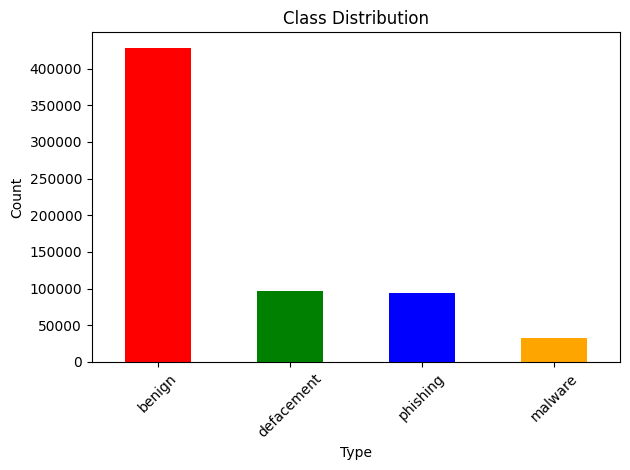

In [4]:
df['type'].value_counts().plot(kind='bar', color=['red','green','blue','orange'])
plt.title('Class Distribution')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
df['label'] = df['type'].apply(lambda x: 0 if x == 'benign' else 1)
print(df['label'].value_counts())
print("\nSample:")
df[['url', 'type', 'label']].head(10)

label
0    428103
1    223088
Name: count, dtype: int64

Sample:


,url,type,label
0,br-icloud.com.br,phishing,1
1,mp3raid.com/music/krizz_kaliko.html,benign,0
2,bopsecrets.org/rexroth/cr/1.htm,benign,0
3,http://www.garage-pirenne.be/index.php?option=...,defacement,1
4,http://adventure-nicaragua.net/index.php?optio...,defacement,1
5,http://buzzfil.net/m/show-art/ils-etaient-loin...,benign,0
6,espn.go.com/nba/player/_/id/3457/brandon-rush,benign,0
7,yourbittorrent.com/?q=anthony-hamilton-soulife,benign,0
8,http://www.pashminaonline.com/pure-pashminas,defacement,1
9,allmusic.com/album/crazy-from-the-heat-r16990,benign,0


In [6]:
from sklearn.utils import resample

benign = df[df['label'] == 0]
malicious = df[df['label'] == 1]

# Undersample benign to match malicious count
benign_undersampled = resample(benign, 
                                replace=False, 
                                n_samples=len(malicious), 
                                random_state=42)

df_balanced = pd.concat([benign_undersampled, malicious])
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

print(df_balanced['label'].value_counts())
print("\nNew shape:", df_balanced.shape)

label
0    223088
1    223088
Name: count, dtype: int64

New shape: (446176, 3)


In [7]:
df_balanced.to_csv('../dataset/balanced_links.csv', index=False)
print("Saved successfully!")

Saved successfully!
